# [Lab Session 2](otsu.ipynb)

In [16]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [17]:
 imgf = plt.imread('data/NIH3T3/im/dna-0.png')

**[Task 1.2.]()** Quantify the image into 256 bins:

In [18]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

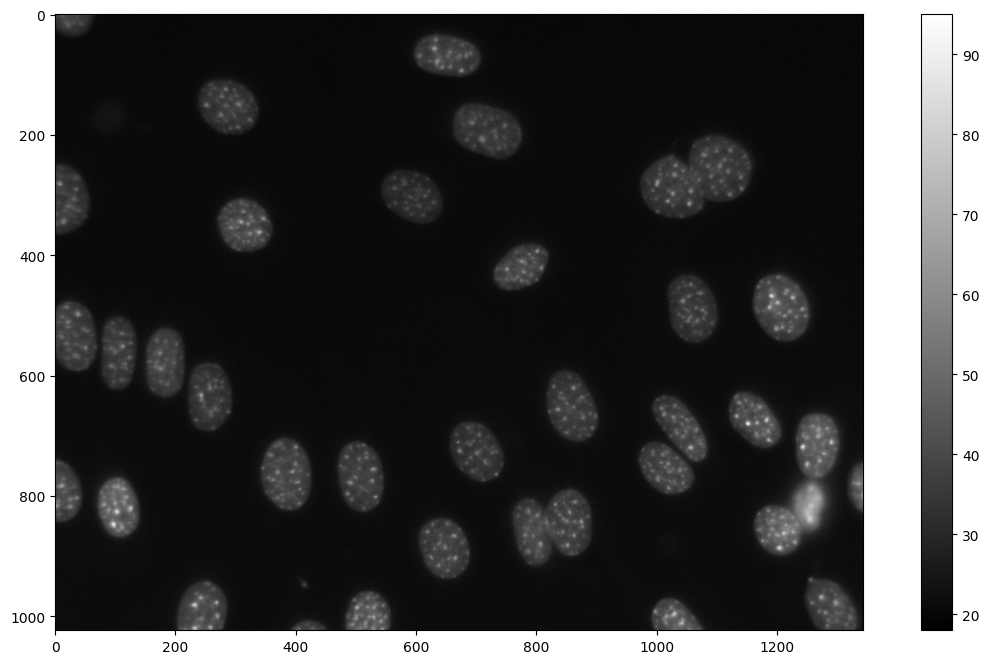

In [ ]:
plt.figure(figsize=(15,8))
plt.imshow(img8, 'grey')
plt.colorbar ()

h= np.zeros(256)

for i in range(256):
    h[i] = np.sum(img8 == i)



Show the computed histogram:

<BarContainer object of 256 artists>

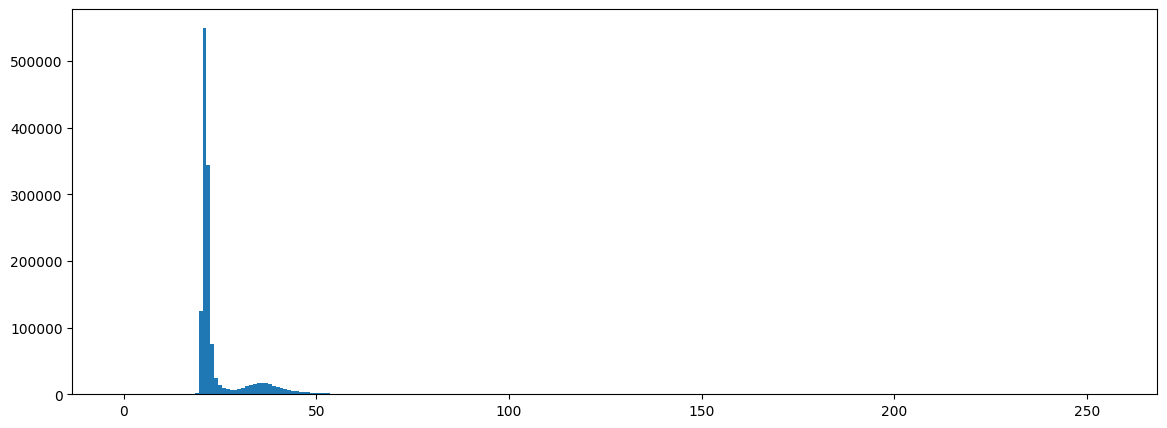

In [25]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [37]:
werte = np.arange(256)
Score = np.full(256, np.inf) #np.inf damit die ersten Stellen nicht 0 bleiben. Alle die nicht 0 sind werden überschrieben.


for i in range(256):
    n1 = h[:i].sum()
    n2 = h[i:].sum()
    if n1 == 0 or n2 == 0: # überspringt Intensitäten, die nicht vorkommen
        continue
    mu1 = np.average(werte[:i], weights=h[:i])
    mu2 = np.average(werte[i:], weights=h[i:])
    var1 = np.average((werte[:i]-mu1)**2, weights=h[:i])
    var2 = np.average((werte[i:]-mu2)**2, weights=h[i:])
    Score[i] = n1*var1 + n2*var2

T = np.argmin(Score)
print(T)

print(Score)

31
[              inf               inf               inf               inf
               inf               inf               inf               inf
               inf               inf               inf               inf
               inf               inf               inf               inf
               inf               inf               inf 62268423.49896931
 62231302.67756924 59818223.62454262 47165648.8532488  27449150.57824365
 18586354.36935249 15253989.89752736 13539656.28011815 12557445.78895864
 11933561.89796724 11536254.18924297 11313729.00229156 11275653.93934225
 11495860.3303481  12094366.78891711 13176916.55272644 14767374.26909976
 16902177.86318459 19466392.13648611 22316940.04301708 25216024.01878978
 28108330.89532448 30810951.55526169 33287950.23202946 35560795.16565559
 37671210.8137913  39656813.25915195 41533993.49633767 43351146.15318058
 45045719.27117065 46595703.72321466 48078570.11368068 49403191.17985922
 50631766.8368401  51670386.5445267  52624546.35

**[Task 1.5.]()** Perform Otsu thresholding:

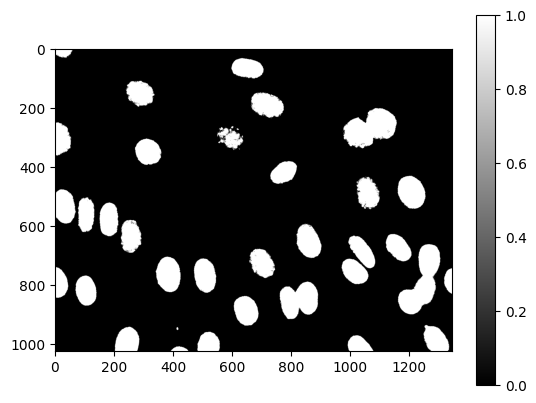

In [35]:
img8_2 = img8.copy()

T = 31

for x in range(1024):
    for y in range (1344):
         if img8_2[x,y] >= T:
            img8_2[x,y] = 1
         else :
            img8_2[x,y] = 0

plt.imshow(img8_2, 'grey' )
plt.colorbar ()

**[Task 1.6.]()** Compute the Dice coefficient:

In [36]:
G = plt.imread('data/NIH3T3/gt/0.png')
H = img8_2

DC = 2*(G*H).sum()/(G.sum() + H.sum())
print(DC)

0.8943783223933183
